# Laboratory 2 (Part II)
### Flat field analysis
(different values for each pixel, quantitatively you know the % of light detected and correct -> "real" = observed %)

In [32]:
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits
import pickle

Import bias value from part I and flat list

In [33]:
bias_std = 1.88
median_bias = pickle.load(open('median_bias.p', 'rb'))

flat_list = np.genfromtxt('group09_HAT-P-12_20200422/flat/flat.list', dtype='str')
print(flat_list)

['AF608293.fits' 'AF608294.fits' 'AF608295.fits' 'AF608296.fits'
 'AF608297.fits' 'AF608298.fits' 'AF608299.fits' 'AF608300.fits'
 'AF608301.fits' 'AF608302.fits' 'AF608303.fits' 'AF608304.fits'
 'AF608305.fits' 'AF608306.fits' 'AF608307.fits' 'AF608308.fits'
 'AF608309.fits' 'AF608310.fits' 'AF608311.fits' 'AF608312.fits'
 'AF608313.fits' 'AF608314.fits' 'AF608315.fits' 'AF608316.fits'
 'AF608317.fits' 'AF608318.fits' 'AF608319.fits' 'AF608320.fits'
 'AF608321.fits' 'AF608322.fits']


## Flat analysis of the first image, then generalize

In [34]:
flat00_fits = fits.open('group09_HAT-P-12_20200422/flat/' + flat_list[0], dtype='str')
flat00_data = flat00_fits[0].data

gain = flat00_fits[0].header['GAIN']
ron = flat00_fits[0].header['RDNOISE']

Plot the first flat and the median along the column or rows

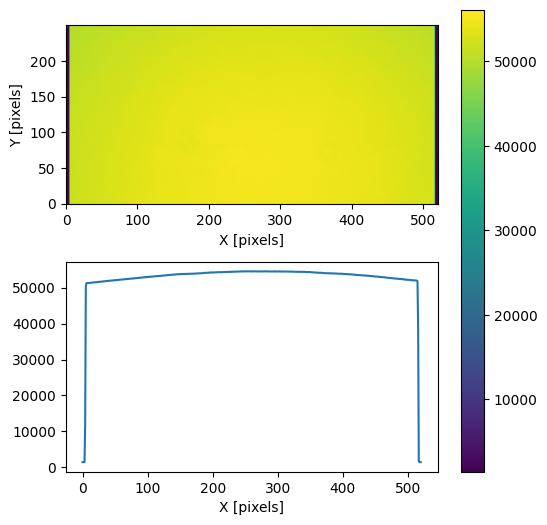

In [35]:
fig, ax = plt.subplots(2,1, figsize=(6,6))
im1 = ax[0].imshow(flat00_data, origin='lower')
median_column = np.average(flat00_data, axis=0)
im2 = ax[1].plot(median_column)
cbar = plt.colorbar(im1, ax=ax)
ax[0].set_xlabel('X [pixels]')
ax[0].set_ylabel('Y [pixels]')
ax[1].set_xlabel('X [pixels]')
plt.show()

Black regions in the flat are not illuminated, bias structure -> standard way is to trim the image (exlude some first and last pixels).

Alternative is to keep region but exlude in plots and while computing quantites like median, std, etc. (what we will do here)

In [ ]:
print(np.shape(flat00_data))
vmin = np.amin(flat00_data[:,13:-13])
vmax = np.amax(flat00_data[:,13:-13])
print(vmin, vmax)

(250, 521)
49586 56108


Plot considering min and max outside the black regions

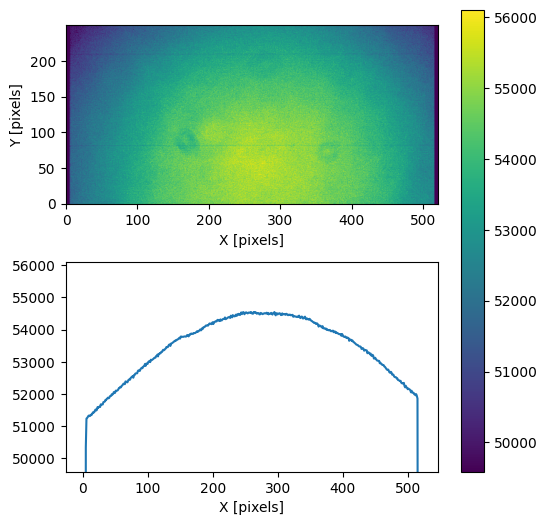

In [37]:
fig, ax = plt.subplots(2,1, figsize=(6,6))
im1 = ax[0].imshow(flat00_data, origin='lower',vmin=vmin, vmax=vmax)
median_column = np.average(flat00_data, axis=0)
im2 = ax[1].plot(median_column)
ax[1].set_ylim(vmin, vmax)
cbar = plt.colorbar(im1, ax=ax)  #first image as reference for colorbar
ax[0].set_xlabel('X [pixels]')
ax[0].set_ylabel('Y [pixels]')
ax[1].set_xlabel('X [pixels]')
plt.show()

Want to normalize the flat image to an area of the image to have relative flux, use a central box of side 50

In [38]:
box_size = 50
y0, y1 = np.int16(np.shape(flat00_data)[0]/2 - box_size/2), np.int16(np.shape(flat00_data)[0]/2 + box_size/2)
x0, x1 = np.int16(np.shape(flat00_data)[1]/2 - box_size/2), np.int16(np.shape(flat00_data)[1]/2 + box_size/2)
print(y0, y1)
print(x0, x1)
normalization_factor = np.median(flat00_data[y0:y1, x0:x1])
print(normalization_factor)

100 150
235 285
54810.0


## Now generalize to all flat images

Use stack as for bias analysis, create and fill. Subtract bias structure and convert to electrons (*gain)

In [39]:
n_images = len(flat_list)
flat00_dim00, flat00_dim01 = np.shape(flat00_data)
stack = np.empty((n_images, flat00_dim00, flat00_dim01))
print(np.shape(stack))

for i_flat, flat_name in enumerate(flat_list):
    flat_temp = fits.open('group09_HAT-P-12_20200422/flat/' + flat_name, dtype='str')
    stack[i_flat,:,:] = flat_temp[0].data * gain - median_bias
    flat_temp.close()

(30, 250, 521)


Compute normalization factor for each image, median of the "box", and plot it

[101906.6175 101455.8575 101867.4625 101471.1375 101934.79   101394.26
 101860.7775 101456.335  101775.305  101794.405  101854.57   101377.07
 101810.1625 101283.48   101792.0175 101336.005  101769.575  101359.88
 101802.045  101242.8925 101780.08   101371.34   101772.9175 101382.8
 101847.885  101317.3825 101824.965  101342.2125 101831.65   101429.595 ]
(30,)


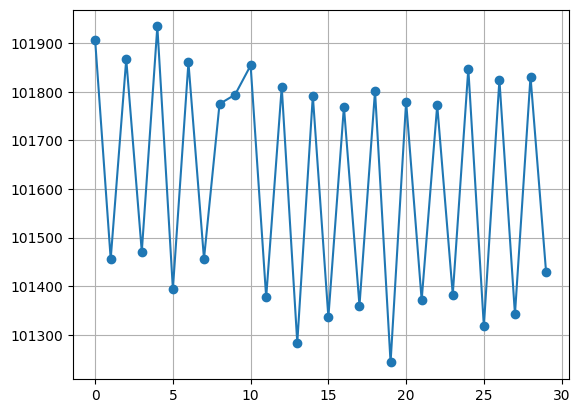

In [40]:
normalization_factors = np.median(stack[:,y0:y1,x0:x1], axis=(1,2))  # median of each image in the stack, frame by frame
print(normalization_factors)
print(np.shape(normalization_factors))

plt.figure()
x_frame = np.arange(0,n_images,1)
plt.plot(x_frame, normalization_factors, '-o')
plt.grid()
plt.show()

Normalize flat inside stack, use transponse for the "shape problem"

In [41]:
print(np.shape(stack))
print(np.shape(stack.T))
print(np.shape(normalization_factors))

stack_normalized = (stack.T / normalization_factors).T
print(np.shape(stack_normalized))

(30, 250, 521)
(521, 250, 30)
(30,)
(30, 250, 521)


Median of the flat along columns or rows and plot

(250, 521)


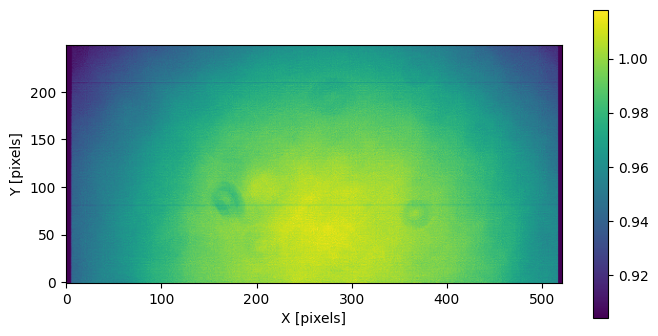

In [42]:
median_normalized_flat = np.median(stack_normalized, axis=0)
print(np.shape(median_normalized_flat))

vmin_flat = np.amin(median_normalized_flat[:,13:-13])
vmax_flat = np.amax(median_normalized_flat[:,13:-13])

fig, ax = plt.subplots(figsize=(8,4))
im1 = ax.imshow(median_normalized_flat, origin='lower',vmin=vmin_flat, vmax=vmax_flat)

cbar = plt.colorbar(im1, ax=ax)
ax.set_xlabel('X [pixels]')
ax.set_ylabel('Y [pixels]')
plt.show()

### Noise sources

- readout noise
- error associated with the median bias
- photon noise (sqrt of flux)

Already subtracted bias in flat stack, so we can compute photon noise as sqrt of the median normalized flat (after *gain, bc photon number)

Sum in quadratures

In [43]:
ron = flat00_fits[0].header['RDNOISE']
photon_noise = np.sqrt(stack)

# print(ron)
# print(bias_std)
# print(photon_noise)

stack_error = np.sqrt(ron**2 + bias_std**2 + photon_noise**2)
# print(stack_error)
print(np.shape(stack_error))

/tmp/ipykernel_4179/1144757881.py:2: RuntimeWarning: invalid value encountered in sqrt
  photon_noise = np.sqrt(stack)


(30, 250, 521)


Normalize error like we did for the flat and sum in quadrature each frame, now we have a single flat normalized image and error

In [44]:
stack_normalized_error = (stack_error.T /normalization_factors).T
print(np.shape(stack_normalized_error))

median_normalized_flat_error = np.sqrt(np.sum(stack_normalized_error**2, axis=0)) / n_images # sum in quadrature
print(np.shape(median_normalized_flat_error))

(30, 250, 521)
(250, 521)


Plot the error frame

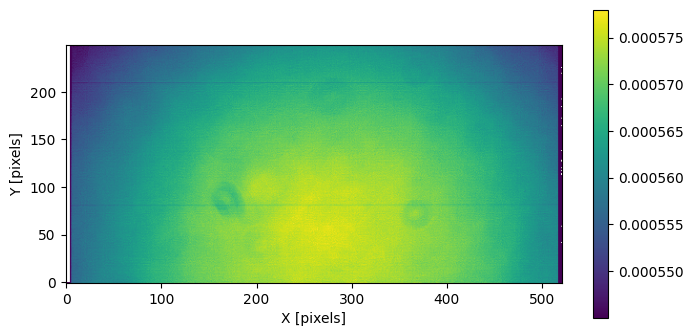

In [45]:
vmin_flat_err = np.amin(median_normalized_flat_error[:,13:-13])  # exclude 13 pixels from each side
vmax_flat_err = np.amax(median_normalized_flat_error[:,13:-13])  # exclude 13 pixels from each side

fig, ax = plt.subplots(figsize=(8,4))
im1 = ax.imshow(median_normalized_flat_error, origin='lower',vmin=vmin_flat_err, vmax=vmax_flat_err)

cbar = plt.colorbar(im1, ax=ax)
ax.set_xlabel('X [pixels]')
ax.set_ylabel('Y [pixels]')
plt.show()

Compute relative error and plot

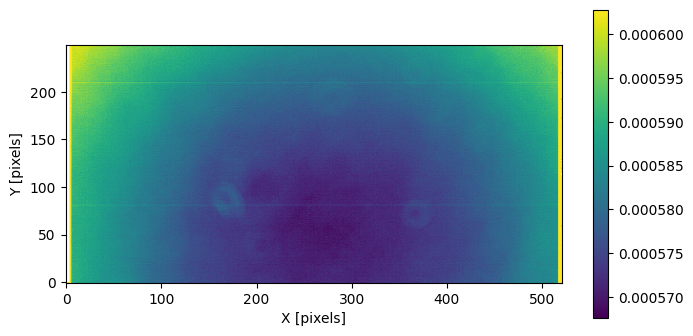

In [46]:
rel_error = median_normalized_flat_error / median_normalized_flat

vmin_rel_err = np.amin(rel_error[:,13:-13])
vmax_rel_err = np.amax(rel_error[:,13:-13])

fig, ax = plt.subplots(figsize=(8,4))
im1 = ax.imshow(rel_error, origin='lower',vmin=vmin_rel_err, vmax=vmax_rel_err)

cbar = plt.colorbar(im1, ax=ax)
ax.set_xlabel('X [pixels]')
ax.set_ylabel('Y [pixels]')
plt.show()

Save normalized flat and error

In [47]:
pickle.dump(median_normalized_flat, open('median_normalized_flat.p', 'wb'))
pickle.dump(median_normalized_flat_error, open('median_normalized_flat_errors.p', 'wb'))